# Taller 09 — Clasificadores Bayesianos


## Objetivo
Construir y evaluar clasificadores Naive Bayes para reconocer los dígitos escritos a mano del dataset `digits` de scikit-learn, usando partición 80/20, validación cruzada con K-fold = 4, una justificación de la distribución de los datos y un análisis del suavizado de Laplace (`alpha`).


Clasificadores a comparar:
- **GaussianNB**
- **MultinomialNB**
- **BernoulliNB**
- **CategoricalNB**

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, CategoricalNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Binarizer

digits = load_digits()
X = digits.data.astype(int)   # enteros 0..16
y = digits.target

print("Dimensiones de X:", X.shape)
print("Clases:", np.unique(y))
print("Intensidad mínima y máxima:", X.min(), X.max())

Dimensiones de X: (1797, 64)
Clases: [0 1 2 3 4 5 6 7 8 9]
Intensidad mínima y máxima: 0 16


## División 80/20 y K-fold = 4
La prueba (20 %) se reserva para el final. Toda la selección de modelo e hiperparámetros se hace con validación cruzada estratificada de 4 folds **solo sobre el 80 % de entrenamiento**.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

print(f"Entrenamiento: {len(X_train)} ({len(X_train)/len(X):.1%})")
print(f"Prueba:        {len(X_test)} ({len(X_test)/len(X):.1%})")
pd.Series(y).value_counts().sort_index().rename("cantidad").to_frame().T

Entrenamiento: 1437 (80.0%)
Prueba:        360 (20.0%)


,0,1,2,3,4,5,6,7,8,9
cantidad,178,182,177,183,181,182,181,179,174,180


### Qué distribución siguen los datos?
Se revisa la distribución de los valores de píxel (global y por clase) para decidir qué modelo probabilístico es razonable.

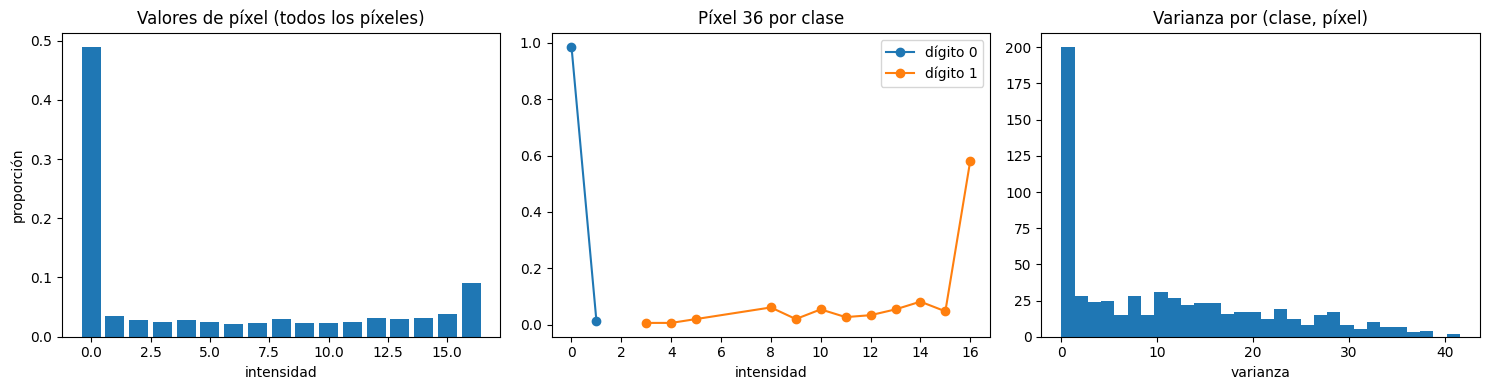

Píxeles con valor 0: 48.9%
Píxeles con valor 16: 9.1%
Pares (clase, píxel) con varianza = 0: 129 de 640


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1) Distribución global de los valores de píxel
vals, cnt = np.unique(X_train, return_counts=True)
ax[0].bar(vals, cnt / cnt.sum())
ax[0].set_title("Valores de píxel (todos los píxeles)")
ax[0].set_xlabel("intensidad"); ax[0].set_ylabel("proporción")

# 2) Un píxel central para dos clases distintas
px = 36
for c in (0, 1):
    v, n = np.unique(X_train[y_train == c, px], return_counts=True)
    ax[1].plot(v, n / n.sum(), marker="o", label=f"dígito {c}")
ax[1].set_title(f"Píxel {px} por clase"); ax[1].set_xlabel("intensidad"); ax[1].legend()

# 3) Píxeles con varianza casi nula dentro de su clase
var_por_clase = np.array([X_train[y_train == c].var(axis=0) for c in range(10)])
ax[2].hist(var_por_clase.ravel(), bins=30)
ax[2].set_title("Varianza por (clase, píxel)"); ax[2].set_xlabel("varianza")
plt.tight_layout(); plt.show()

print(f"Píxeles con valor 0: {(X_train == 0).mean():.1%}")
print(f"Píxeles con valor 16: {(X_train == 16).mean():.1%}")
print(f"Pares (clase, píxel) con varianza = 0: {(var_por_clase == 0).sum()} de {var_por_clase.size}")

### Conclusión sobre la distribución
- Los datos son **discretos y acotados**, no continuos.
- la distribución que describe mejor cada píxel es la **categórica** (17 niveles posibles). Multinomial y Gaussiana son aproximaciones, y Bernoulli pierde información al binarizar.


## Comparación inicial con parámetros por defecto
Se usa `alpha=1` (Laplace clásico) en los modelos discretos, `var_smoothing=1e-9` (valor por defecto) en GaussianNB, y umbral 0 en Bernoulli.

In [4]:
base = {
    "GaussianNB (defecto)": GaussianNB(),
    "MultinomialNB (alpha=1)": MultinomialNB(alpha=1.0),
    "BernoulliNB (umbral 0, alpha=1)": make_pipeline(Binarizer(threshold=0.0), BernoulliNB(alpha=1.0)),
    "CategoricalNB (alpha=1)": CategoricalNB(alpha=1.0, min_categories=17),
}
rows = []
for n, m in base.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"Modelo": n, "Accuracy CV": s.mean(), "Desv. est.": s.std()})
pd.DataFrame(rows).sort_values("Accuracy CV", ascending=False).round(4)

,Modelo,Accuracy CV,Desv. est.
3,CategoricalNB (alpha=1),0.9068,0.0170
1,MultinomialNB (alpha=1),0.9047,0.0114
2,"BernoulliNB (umbral 0, alpha=1)",0.8546,0.0052
0,GaussianNB (defecto),0.8232,0.0050


Con sus parámetros por defecto GaussianNB queda de último, pero esa comparación **no es justa**: cada modelo tiene un hiperparámetro de suavizado que hay que ajustar antes de compararlos. Se hace a continuación.

In [5]:
def cv_acc(model):
    s = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    return s.mean(), s.std()

grids = {
    "GaussianNB":    ("var_smoothing", [1e-9, 1e-6, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0],
                      lambda p: GaussianNB(var_smoothing=p)),
    "MultinomialNB": ("alpha", [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
                      lambda p: MultinomialNB(alpha=p)),
    "CategoricalNB": ("alpha", [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
                      lambda p: CategoricalNB(alpha=p, min_categories=17)),
    "BernoulliNB (umbral 8)": ("alpha", [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
                      lambda p: make_pipeline(Binarizer(threshold=8.0), BernoulliNB(alpha=p))),
}
best = {}
for name, (pname, vals, mk) in grids.items():
    res = [(v, *cv_acc(mk(v))) for v in vals]
    v_best, m_best, s_best = max(res, key=lambda r: r[1])
    best[name] = dict(param=pname, value=v_best, cv=m_best, std=s_best, make=mk)

summary = pd.DataFrame({k: {"Hiperparámetro": v["param"], "Mejor valor": v["value"],
                            "Accuracy CV": v["cv"], "Desv. est.": v["std"]} for k, v in best.items()}).T
summary["Accuracy CV"] = summary["Accuracy CV"].astype(float).round(4)
summary["Desv. est."] = summary["Desv. est."].astype(float).round(4)
summary.sort_values("Accuracy CV", ascending=False)

,Hiperparámetro,Mejor valor,Accuracy CV,Desv. est.
GaussianNB,var_smoothing,0.1,0.9248,0.0076
CategoricalNB,alpha,0.5,0.9088,0.0169
MultinomialNB,alpha,0.1,0.9047,0.0114
BernoulliNB (umbral 8),alpha,0.01,0.8880,0.0160


### Selección del clasificador
Se elige el de mayor accuracy promedio en CV Después se analiza el suavizado: `var_smoothing` en el modelo elegido y Laplace (`alpha`) en los modelos discretos, incluido CategoricalNB, que es el que corresponde a la distribución de los datos.

In [6]:
chosen_name = max(best, key=lambda k: best[k]["cv"])
print("Clasificador elegido por CV:", chosen_name)
print("Hiperparámetro:", best[chosen_name]["param"], "=", best[chosen_name]["value"])
print(f"Accuracy CV: {best[chosen_name]['cv']:.4f} ± {best[chosen_name]['std']:.4f}")

Clasificador elegido por CV: GaussianNB
Hiperparámetro: var_smoothing = 0.1
Accuracy CV: 0.9248 ± 0.0076


## Efecto del suavizado en GaussianNB
En una gaussiana no hay conteos, así que no existe Laplace literal. `var_smoothing` cumple un papel análogo: evita varianzas cero (el equivalente a probabilidades cero).

,var_smoothing,Accuracy,Precision macro,Recall macro,F1 macro
0,0.000,0.8232,0.8652,0.8233,0.8240
1,0.000,0.8734,0.8913,0.8733,0.8750
2,0.001,0.9075,0.9136,0.9076,0.9077
3,0.010,0.9193,0.9232,0.9193,0.9193
4,0.030,0.9235,0.9268,0.9234,0.9235
5,0.100,0.9248,0.9282,0.9249,0.9250
6,0.300,0.9214,0.9245,0.9214,0.9213
7,1.000,0.9068,0.9091,0.9067,0.9063
8,3.000,0.8977,0.9009,0.8977,0.8969


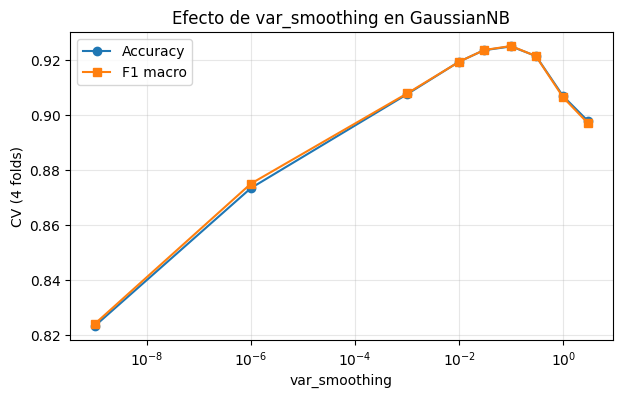

In [7]:
vs_list = [1e-9, 1e-6, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0, 3.0]
rows = []
for v in vs_list:
    m = GaussianNB(var_smoothing=v)
    pred_cv = []
    accs, precs, recs, f1s = [], [], [], []
    for tr, va in cv.split(X_train, y_train):
        m.fit(X_train[tr], y_train[tr]); p = m.predict(X_train[va]); t = y_train[va]
        accs.append(accuracy_score(t, p))
        precs.append(precision_score(t, p, average="macro", zero_division=0))
        recs.append(recall_score(t, p, average="macro", zero_division=0))
        f1s.append(f1_score(t, p, average="macro", zero_division=0))
    rows.append({"var_smoothing": v, "Accuracy": np.mean(accs), "Precision macro": np.mean(precs),
                 "Recall macro": np.mean(recs), "F1 macro": np.mean(f1s)})
vs_table = pd.DataFrame(rows)
display(vs_table.round(4))

plt.figure(figsize=(7, 4))
plt.semilogx(vs_table["var_smoothing"], vs_table["Accuracy"], marker="o", label="Accuracy")
plt.semilogx(vs_table["var_smoothing"], vs_table["F1 macro"], marker="s", label="F1 macro")
plt.xlabel("var_smoothing"); plt.ylabel("CV (4 folds)"); plt.grid(alpha=.3); plt.legend()
plt.title("Efecto de var_smoothing en GaussianNB"); plt.show()


=== CategoricalNB ===


,alpha,Accuracy,Precision macro,Recall macro,F1 macro
0,0.00,0.5372,0.8261,0.5380,0.5942
1,0.01,0.8970,0.9025,0.8970,0.8972
2,0.10,0.9061,0.9096,0.9059,0.9061
3,0.50,0.9088,0.9108,0.9086,0.9085
4,1.00,0.9068,0.9091,0.9064,0.9061
5,2.00,0.8970,0.9009,0.8965,0.8964
6,5.00,0.8859,0.8956,0.8851,0.8853
7,10.00,0.8636,0.8829,0.8626,0.8632
8,50.00,0.7933,0.8627,0.7912,0.7874



=== MultinomialNB ===


,alpha,Accuracy,Precision macro,Recall macro,F1 macro
0,0.00,0.0988,0.0099,0.1000,0.0180
1,0.01,0.9040,0.9117,0.9041,0.9042
2,0.10,0.9047,0.9121,0.9048,0.9050
3,0.50,0.9047,0.9121,0.9048,0.9050
4,1.00,0.9047,0.9121,0.9048,0.9050
5,2.00,0.9047,0.9118,0.9048,0.9049
6,5.00,0.9040,0.9111,0.9041,0.9043
7,10.00,0.9040,0.9111,0.9041,0.9043
8,50.00,0.9054,0.9117,0.9054,0.9055



=== BernoulliNB ===


,alpha,Accuracy,Precision macro,Recall macro,F1 macro
0,0.00,0.0988,0.0099,0.1000,0.0180
1,0.01,0.8880,0.8942,0.8879,0.8886
2,0.10,0.8859,0.8919,0.8858,0.8865
3,0.50,0.8831,0.8887,0.8831,0.8837
4,1.00,0.8845,0.8904,0.8845,0.8851
5,2.00,0.8817,0.8866,0.8817,0.8823
6,5.00,0.8761,0.8804,0.8760,0.8767
7,10.00,0.8713,0.8749,0.8710,0.8714
8,50.00,0.8629,0.8658,0.8624,0.8618


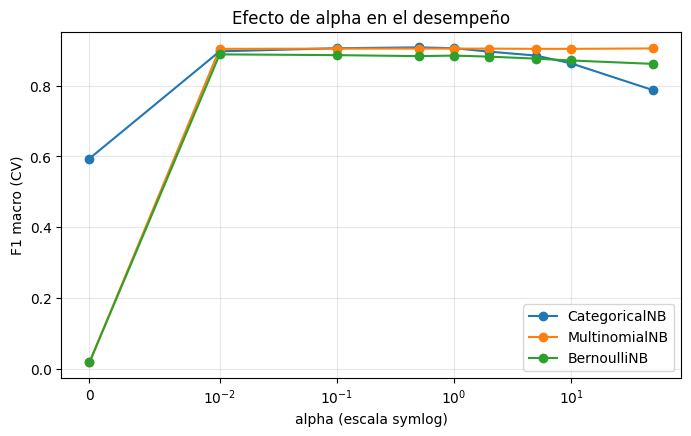

In [8]:
alphas = [0.0, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]

def make_discrete(name, a):
    if name == "CategoricalNB": return CategoricalNB(alpha=a, min_categories=17)
    if name == "MultinomialNB": return MultinomialNB(alpha=a)
    return make_pipeline(Binarizer(threshold=8.0), BernoulliNB(alpha=a))

def cv_metrics(model):
    A, P, R, F = [], [], [], []
    for tr, va in cv.split(X_train, y_train):
        model.fit(X_train[tr], y_train[tr]); p = model.predict(X_train[va]); t = y_train[va]
        A.append(accuracy_score(t, p))
        P.append(precision_score(t, p, average="macro", zero_division=0))
        R.append(recall_score(t, p, average="macro", zero_division=0))
        F.append(f1_score(t, p, average="macro", zero_division=0))
    return np.mean(A), np.mean(P), np.mean(R), np.mean(F)

alpha_tables = {}
for name in ["CategoricalNB", "MultinomialNB", "BernoulliNB"]:
    rows = []
    for a in alphas:
        # alpha=0 se pasa como 0; sklearn lo sustituye internamente por 1e-10
        A, P, R, F = cv_metrics(make_discrete(name, a))
        rows.append({"alpha": a, "Accuracy": A, "Precision macro": P, "Recall macro": R, "F1 macro": F})
    alpha_tables[name] = pd.DataFrame(rows)
    print(f"\n=== {name} ===")
    display(alpha_tables[name].round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, t in alpha_tables.items():
    ax.plot(t["alpha"], t["F1 macro"], marker="o", label=name)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlabel("alpha (escala symlog)"); ax.set_ylabel("F1 macro (CV)")
ax.set_title("Efecto de alpha en el desempeño"); ax.grid(alpha=.3); ax.legend(); plt.show()

### Lectura de los resultados
- **`alpha = 0`** hunde el desempeño: en MultinomialNB y BernoulliNB cae a ~10 % (azar con 10 clases), y en CategoricalNB a ~54 %, porque basta una probabilidad cero para anular toda la clase.
- **`alpha` pequeño a moderado (0,01–2)** da el mejor desempeño y es casi estable: las diferencias entre estos valores están dentro de la desviación entre folds, así que no conviene leer un "mejor alpha" exacto.
- **`alpha` grande** suaviza en exceso, pero el efecto depende del modelo. En CategoricalNB (17 categorías por píxel y pocos datos por categoría) la caída es fuerte (accuracy ~0,79 con `alpha=50`). En BernoulliNB baja de forma gradual. En MultinomialNB casi no cambia, porque las frecuencias acumuladas por píxel son grandes (sumas de intensidades) y `alpha` es pequeño frente a ellas.
- Accuracy, precision, recall y F1 se mueven juntos, ya que las clases están casi balanceadas.

## Modelo final y evaluación en prueba
Se entrena con todo el 80 % y se evalúa **una sola vez** en el 20 % reservado. Se reporta el clasificador elegido por CV y, como referencia, CategoricalNB (el modelo que corresponde a la distribución categórica de los datos y al que se le aplica Laplace directamente).

In [9]:
cat_t = alpha_tables["CategoricalNB"]
cat_alpha = float(cat_t.loc[cat_t["Accuracy"].idxmax(), "alpha"])

finales = {
    f"{chosen_name} ({best[chosen_name]['param']}={best[chosen_name]['value']})":
        best[chosen_name]["make"](best[chosen_name]["value"]),
    f"CategoricalNB (alpha={cat_alpha})": CategoricalNB(alpha=cat_alpha, min_categories=17),
}
rows, preds = [], {}
for n, m in finales.items():
    m.fit(X_train, y_train); p = m.predict(X_test); preds[n] = p
    rows.append({"Modelo": n, "Accuracy": accuracy_score(y_test, p),
                 "Precision macro": precision_score(y_test, p, average="macro"),
                 "Recall macro": recall_score(y_test, p, average="macro"),
                 "F1 macro": f1_score(y_test, p, average="macro")})
pd.DataFrame(rows).round(4)

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro
0,GaussianNB (var_smoothing=0.1),0.9222,0.9224,0.9220,0.9211
1,CategoricalNB (alpha=0.5),0.9111,0.9121,0.9108,0.9107


GaussianNB (var_smoothing=0.1)
              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.8182    0.7500    0.7826        36
           2     0.8718    0.9714    0.9189        35
           3     1.0000    0.9459    0.9722        37
           4     0.9730    1.0000    0.9863        36
           5     0.9714    0.9189    0.9444        37
           6     0.9722    0.9722    0.9722        36
           7     0.9000    1.0000    0.9474        36
           8     0.8750    0.8000    0.8358        35
           9     0.8421    0.8889    0.8649        36

    accuracy                         0.9222       360
   macro avg     0.9224    0.9220    0.9211       360
weighted avg     0.9230    0.9222    0.9215       360



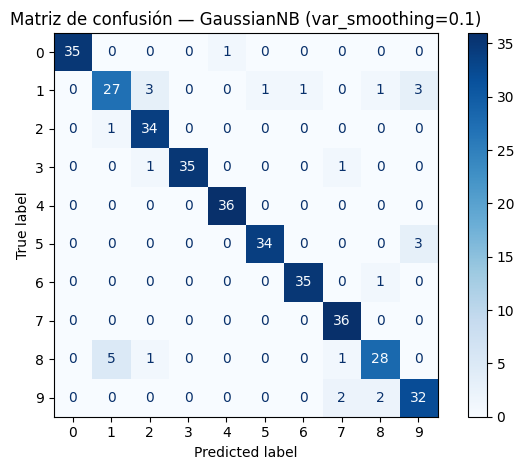

Confusiones más frecuentes (real → predicho, cantidad): [(8, 1, np.int64(5)), (1, 2, np.int64(3)), (1, 9, np.int64(3)), (5, 9, np.int64(3)), (9, 7, np.int64(2))]


In [10]:
n0 = list(finales)[0]
print(n0); print(classification_report(y_test, preds[n0], digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, preds[n0], cmap="Blues")
plt.title(f"Matriz de confusión — {n0}"); plt.tight_layout(); plt.show()

# pares de dígitos más confundidos
cm = pd.crosstab(pd.Series(y_test, name="real"), pd.Series(preds[n0], name="predicho"))
conf = [(i, j, cm.loc[i, j]) for i in cm.index for j in cm.columns if i != j and cm.loc[i, j] > 0]
print("Confusiones más frecuentes (real → predicho, cantidad):", sorted(conf, key=lambda t: -t[2])[:5])

## Conclusiones
Las cifras exactas están en las tablas de arriba; aquí se resume su interpretación.
1. **Datos:** 1.797 imágenes, 64 características enteras, 10 clases casi balanceadas. Partición estratificada 80/20 y K-fold = 4 solo sobre entrenamiento.
2. **Distribución:** los píxeles son discretos, acotados y muy asimétricos, así que **no son normales**. La distribución que mejor los describe es la **categórica**; Multinomial y Gaussiana son aproximaciones.
3. **Laplace:** `alpha=0` destruye el clasificador en los modelos discretos (probabilidades cero), valores pequeños a moderados rinden casi igual, y valores grandes suavizan en exceso y degradan las métricas, sobre todo en CategoricalNB.
4. **Elección:** CategoricalNB es la alternativa coherente con la distribución de los datos y con el uso literal del suavizado de Laplace, con un desempeño cercano.